# 04 - CNN senza data augmentation

In questo notebook alleno da zero una piccola CNN, **senza data augmentation**, per confrontarla con i modelli baseline (RQ1). Il miglior baseline era la SVM su feature PCA in scala di grigi, con accuracy di test 0.939, che sale a 0.988 se si rimuove lo sfondo verde replicando la procedura dell'autore del dataset. L'augmentation arriverà nel notebook successivo.

Passi: caricamento dati, definizione del modello, 5 seed sullo split ufficiale, curve di apprendimento, dimensione e velocità, analisi degli errori, confronto con le baseline ed esperimento sul leakage.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

EPOCHS = 100  # limite di epoche, uguale in tutti i notebook CNN
SEEDS = [0, 1, 2, 3, 4]
SEEDS_LEAK = [0, 1, 2]

FIG_DIR = '../results/figures'
MET_DIR = '../results/metrics'
MOD_DIR = '../data.nosync/models'
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MET_DIR, exist_ok=True)
os.makedirs(MOD_DIR, exist_ok=True)

CLASSES = ['paper', 'rock', 'scissors']

## Dati
Carico lo split ufficiale (a gruppi) e porto i pixel in [0, 1].

In [2]:
d = np.load('../data.nosync/processed/rps_150x100.npz')
X_train = d['X_train'].astype('float32') / 255
y_train = d['y_train']
X_val = d['X_val'].astype('float32') / 255
y_val = d['y_val']
X_test = d['X_test'].astype('float32') / 255
y_test = d['y_test']

print('train:', X_train.shape, y_train.shape)
print('val:  ', X_val.shape, y_val.shape)
print('test: ', X_test.shape, y_test.shape)
print('classi:', CLASSES)

train: (1536, 100, 150, 3) (1536,)
val:   (326, 100, 150, 3) (326,)
test:  (326, 100, 150, 3) (326,)
classi: ['paper', 'rock', 'scissors']


## Modello

La rete ha tre blocchi `Conv2D` + `MaxPooling2D` con 32, 64 e 128 filtri, poi `GlobalAveragePooling2D`, `Dropout(0.5)` e un `Dense` finale con softmax.

- **Conv2D 3x3 (relu, padding same)**: filtri che scorrono sull'immagine e cercano pattern locali (bordi, contorni delle dita). Con `padding='same'` la dimensione non cala a ogni convoluzione.
- **MaxPooling2D 2x2**: dimezza altezza e larghezza tenendo il valore massimo; riduce i calcoli e rende la rete meno sensibile a piccoli spostamenti della mano.
- **GlobalAveragePooling2D**: fa la media di ogni mappa di feature, così evito un `Flatten` seguito da un Dense enorme (che avrebbe molti parametri).
- **Dropout(0.5)**: durante il training spegne a caso metà delle unità, per limitare l'overfitting.
- **Dense(3, softmax)**: dà la probabilità delle tre classi.

È più piccola del modello visto a lezione (due blocchi da 64 e 128 filtri, con due convoluzioni ciascuno): qui ho solo 3 classi e circa 1500 immagini di training, quindi una rete grande avrebbe più rischio di overfitting e sarebbe più lenta da allenare per nessun vantaggio evidente.

In [3]:
def crea_cnn():
    model = keras.Sequential([
        keras.layers.Input(shape=(100, 150, 3)),
        keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Conv2D(128, kernel_size=(3, 3), activation='relu', padding='same'),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.GlobalAveragePooling2D(),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(3, activation='softmax'),
    ])
    return model

model = crea_cnn()
model.summary()
print('Parametri totali:', model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 100, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 25, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,635 (365.76 KB)

 Trainable params: 93,635 (365.76 KB)

 Non-trainable params: 0 (0.00 B)

Parametri totali: 93635


## Training

La funzione `allena` crea una rete nuova, fissa il seed e allena con Adam (lr 1e-3), batch 32 e al massimo `EPOCHS = 100` epoche. L'early stopping guarda la `val_loss` (pazienza 8) e ripristina i pesi della migliore epoca. Passo il validation set dello split a gruppi con `validation_data`, **non** `validation_split`, che ignorerebbe i gruppi.

Con un limite di 50 epoche 3 seed su 5 si erano fermati proprio al limite, quindi lo alzo a 100 e lascio decidere all'early stopping; nel notebook con l'augmentation userò lo stesso limite, così il confronto è equo.

In [4]:
def allena(seed, Xtr, ytr, Xva, yva):
    keras.utils.set_random_seed(seed)
    model = crea_cnn()
    model.compile(loss='sparse_categorical_crossentropy',
                  optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  metrics=['accuracy'])
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=8,
                                               restore_best_weights=True)]
    t0 = time.time()
    history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
                        batch_size=32, epochs=EPOCHS,
                        callbacks=callbacks, verbose=0)
    secondi = time.time() - t0
    return model, history, secondi


def valuta(model, X, y):
    y_pred = np.argmax(model.predict(X, verbose=0), axis=1)
    acc = accuracy_score(y, y_pred)
    f1 = f1_score(y, y_pred, average='macro')
    return y_pred, acc, f1

## Run principali (5 seed, split ufficiale)
Per ogni seed salvo il modello, le metriche e le predizioni sul test (serviranno per i test statistici).

In [5]:
righe = []
pred_righe = []
modelli = {}
storie = {}

for seed in SEEDS:
    model, history, secondi = allena(seed, X_train, y_train, X_val, y_val)
    h = history.history
    epoche = len(h['loss'])
    migliore = int(np.argmin(h['val_loss'])) + 1

    _, acc_va, f1_va = valuta(model, X_val, y_val)
    y_pred, acc_te, f1_te = valuta(model, X_test, y_test)

    model.save(MOD_DIR + f'/cnn_noaug_seed{seed}.keras')
    modelli[seed] = model
    storie[seed] = h

    righe.append({'seed': seed, 'epochs_run': epoche, 'best_epoch': migliore,
                  'val_accuracy': acc_va, 'val_macro_f1': f1_va,
                  'test_accuracy': acc_te, 'test_macro_f1': f1_te,
                  'train_time_s': secondi})
    for i in range(len(y_test)):
        pred_righe.append({'seed': seed, 'idx': i, 'y_true': int(y_test[i]), 'y_pred': int(y_pred[i])})
    print(f'seed {seed}: epoche {epoche}, migliore {migliore}, val acc {acc_va:.3f}, '
          f'test acc {acc_te:.3f}, test F1 {f1_te:.3f}, tempo {secondi:.0f}s')

runs = pd.DataFrame(righe)
runs.to_csv(MET_DIR + '/cnn_noaug_runs.csv', index=False)
pd.DataFrame(pred_righe).to_csv(MET_DIR + '/cnn_noaug_test_predictions.csv', index=False)
runs.round(4)

seed 0: epoche 79, migliore 71, val acc 0.994, test acc 0.988, test F1 0.988, tempo 201s


seed 1: epoche 46, migliore 38, val acc 0.988, test acc 0.982, test F1 0.982, tempo 118s


seed 2: epoche 86, migliore 78, val acc 0.991, test acc 0.985, test F1 0.985, tempo 220s


seed 3: epoche 40, migliore 32, val acc 0.994, test acc 0.982, test F1 0.981, tempo 103s


seed 4: epoche 85, migliore 77, val acc 0.994, test acc 0.988, test F1 0.988, tempo 217s


,seed,epochs_run,best_epoch,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1,train_time_s
0,0,79,71,0.9939,0.9938,0.9877,0.9877,201.3500
1,1,46,38,0.9877,0.9878,0.9816,0.9816,118.1199
2,2,86,78,0.9908,0.9908,0.9847,0.9846,219.9452
3,3,40,32,0.9939,0.9938,0.9816,0.9815,102.7342
4,4,85,77,0.9939,0.9939,0.9877,0.9877,216.9011


In [6]:
acc_media, acc_std = runs['test_accuracy'].mean(), runs['test_accuracy'].std()
f1_media, f1_std = runs['test_macro_f1'].mean(), runs['test_macro_f1'].std()
print(f'Test accuracy: {acc_media:.4f} +- {acc_std:.4f}')
print(f'Test macro-F1: {f1_media:.4f} +- {f1_std:.4f}')

Test accuracy: 0.9847 +- 0.0031
Test macro-F1: 0.9846 +- 0.0031


## Curve di apprendimento (seed 0)

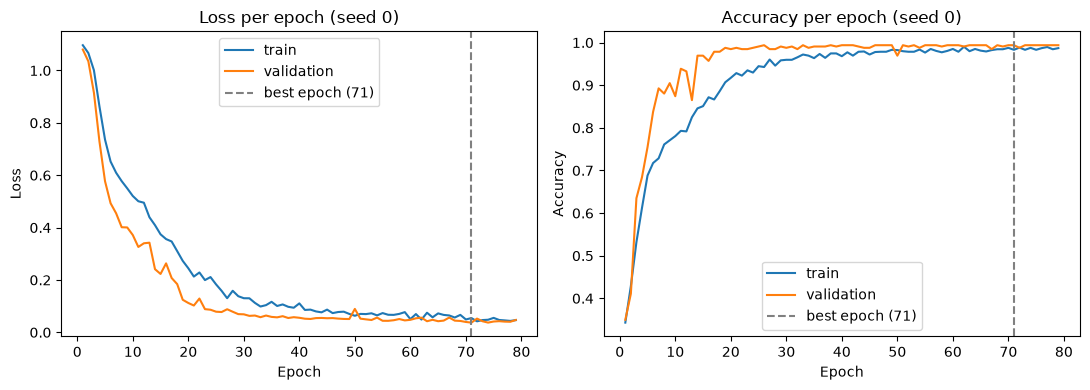

In [7]:
h = storie[0]
migliore = int(runs.loc[runs['seed'] == 0, 'best_epoch'].iloc[0])
ep = np.arange(1, len(h['loss']) + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h['loss'], label='train')
ax[0].plot(ep, h['val_loss'], label='validation')
ax[0].axvline(migliore, color='gray', linestyle='--', label=f'best epoch ({migliore})')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')
ax[0].set_title('Loss per epoch (seed 0)')
ax[0].legend()

ax[1].plot(ep, h['accuracy'], label='train')
ax[1].plot(ep, h['val_accuracy'], label='validation')
ax[1].axvline(migliore, color='gray', linestyle='--', label=f'best epoch ({migliore})')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].set_title('Accuracy per epoch (seed 0)')
ax[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR + '/cnn_learning_curves.png', dpi=150)
plt.show()


Dalle curve del seed 0 non vedo overfitting: la loss di train e quella di validation scendono insieme e a fine training sono praticamente uguali (circa 0.05 e 0.04), e anche le accuracy sono vicine (circa 0.99). Se ci fosse overfitting vedrei la validation loss risalire mentre la train loss continua a scendere, invece dopo la migliore epoca (71) la validation loss resta piatta e l'early stopping interviene all'epoca 79.

La loss di train è più alta di quella di validation per quasi tutto il training, e anche questo è normale e non è un bug, per due motivi. Primo, il Dropout è attivo solo in training, quindi la rete di train lavora "con metà delle unità spente", mentre in validation usa tutte le unità. Secondo, la loss di train è una media calcolata durante l'epoca, mentre i pesi cambiano a ogni batch, quindi include anche i batch dell'inizio epoca quando la rete era peggiore; la validation invece è calcolata a fine epoca con i pesi aggiornati.

Con il limite a 100 epoche nessun seed si ferma più al tetto: i seed si fermano a 79, 46, 86, 40 e 85 epoche, quindi decide l'early stopping. La validation accuracy è instabile nelle prime epoche (per esempio la caduta intorno all'epoca 13) poi si stabilizza.


## Dimensione e velocità
Questi numeri mi serviranno per il confronto con MobileNet (RQ4). Uso il modello del seed 0; faccio un predict di riscaldamento prima di misurare.

In [8]:
model = modelli[0]
n_param = model.count_params()
dim_mb = os.path.getsize(MOD_DIR + '/cnn_noaug_seed0.keras') / (1024 * 1024)

model.predict(X_test, verbose=0)  # warm-up
t0 = time.time()
model.predict(X_test, verbose=0)
ms_img = (time.time() - t0) / len(X_test) * 1000

size = pd.DataFrame([{'model': 'CNN no augmentation', 'n_params': n_param,
                      'size_mb': dim_mb, 'pred_time_ms_per_image': ms_img}])
size.to_csv(MET_DIR + '/cnn_noaug_size.csv', index=False)
print(f'Parametri: {n_param}')
print(f'Dimensione su disco: {dim_mb:.2f} MB')
print(f'Tempo di predizione: {ms_img:.3f} ms per immagine')

Parametri: 93635
Dimensione su disco: 1.11 MB
Tempo di predizione: 0.480 ms per immagine


## Analisi degli errori sul test (seed 0)

              precision    recall  f1-score   support

       paper      0.990     0.972     0.981       106
        rock      0.991     1.000     0.995       108
    scissors      0.982     0.991     0.987       112

    accuracy                          0.988       326
   macro avg      0.988     0.988     0.988       326
weighted avg      0.988     0.988     0.988       326

[[103   1   2]
 [  0 108   0]
 [  1   0 111]]


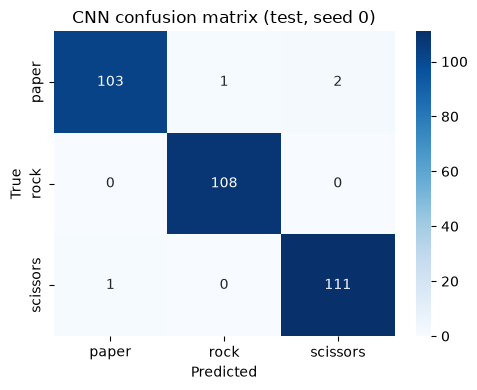

In [9]:
y_pred = np.argmax(modelli[0].predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_test, y_pred)
print(cm)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('CNN confusion matrix (test, seed 0)')
plt.tight_layout()
plt.savefig(FIG_DIR + '/cnn_confusion_matrix.png', dpi=150)
plt.show()

Immagini sbagliate: 4


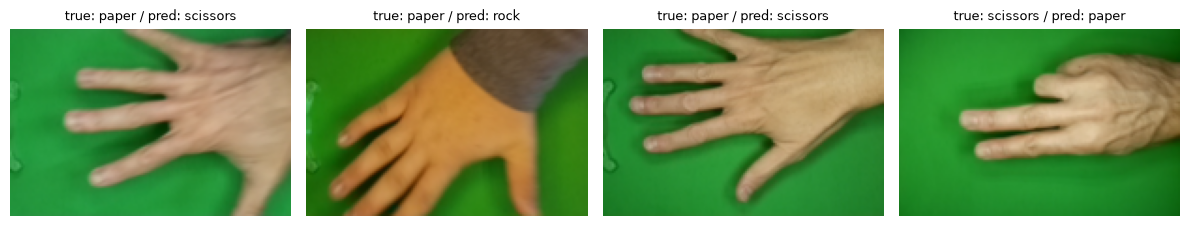

In [10]:
sbagliati = np.where(y_pred != y_test)[0]
print('Immagini sbagliate:', len(sbagliati))

if len(sbagliati) == 0:
    print('Nessun errore sul test set.')
else:
    n = len(sbagliati)
    colonne = min(n, 5)
    righe_fig = int(np.ceil(n / colonne))
    fig, ax = plt.subplots(righe_fig, colonne, figsize=(3 * colonne, 2.4 * righe_fig), squeeze=False)
    for a in ax.ravel():
        a.axis('off')
    for k, i in enumerate(sbagliati):
        a = ax[k // colonne, k % colonne]
        a.imshow(X_test[i])
        a.set_title(f'true: {CLASSES[y_test[i]]} / pred: {CLASSES[y_pred[i]]}', fontsize=9)
    plt.tight_layout()
    plt.savefig(FIG_DIR + '/cnn_errors.png', dpi=150)
    plt.show()

## Confronto con le baseline (RQ1)

In [11]:
base = pd.read_csv(MET_DIR + '/baseline_test.csv')

tabella = []
for nome, feat, etichetta in [('LogReg', 'gray', 'LogReg (gray, PCA)'),
                              ('kNN', 'gray', 'kNN (gray, PCA)'),
                              ('SVM', 'gray', 'SVM (gray, PCA)'),
                              ('SVM', 'gray_no_background', 'SVM (no background, PCA)')]:
    r = base[(base['model'] == nome) & (base['features'] == feat)].iloc[0]
    tabella.append({'modello': etichetta,
                    'test_accuracy': r['test_accuracy'], 'test_macro_f1': r['test_macro_f1'],
                    'acc_std': np.nan, 'f1_std': np.nan})
tabella.append({'modello': f'CNN no augmentation (mean of {len(SEEDS)} seeds)',
                'test_accuracy': acc_media, 'test_macro_f1': f1_media,
                'acc_std': acc_std, 'f1_std': f1_std})

confronto = pd.DataFrame(tabella)
confronto.to_csv(MET_DIR + '/cnn_vs_baseline.csv', index=False)
confronto.round(4)

,modello,test_accuracy,test_macro_f1,acc_std,f1_std
0,"LogReg (gray, PCA)",0.6810,0.6815,NaN,NaN
1,"kNN (gray, PCA)",0.8926,0.8928,NaN,NaN
2,"SVM (gray, PCA)",0.9387,0.9387,NaN,NaN
3,"SVM (no background, PCA)",0.9877,0.9877,NaN,NaN
4,CNN no augmentation (mean of 5 seeds),0.9847,0.9846,0.0031,0.0031



La CNN senza augmentation arriva a 0.985 ± 0.003 di accuracy (e macro-F1) sul test, contro 0.939 della SVM in scala di grigi con PCA: un guadagno di circa 5 punti. Rispetto alla SVM con rimozione dello sfondo (0.988) invece non c'è differenza apprezzabile: 0.985 è dentro la variabilità tra seed (±0.003) e il test ha solo 326 immagini, quindi non posso dire che una sia meglio dell'altra.

La differenza vera sta in cosa serve a ciascun modello. La CNN usa le immagini a colori 150x100 così come sono, senza nessun preprocessing fatto a mano, mentre la SVM da 0.988 dipende dalla rimozione dello sfondo verde che ho replicato dal lavoro dell'autore del dataset. Quindi la CNN ottiene lo stesso livello senza la procedura manuale, ma in cambio ha più parametri (93.635), richiede un training più lungo (da circa 100 a 220 secondi su CPU) ed è più lenta in predizione (0.48 ms per immagine, contro 0.014 ms della SVM, che però misura solo il predict sulle componenti PCA, senza la rimozione dello sfondo).


## Leakage con la CNN

Con i modelli classici la differenza tra split casuale e split a gruppi era dentro il rumore. La CNN però può memorizzare di più, quindi ripeto l'esperimento: per ogni seed (0, 1, 2) costruisco uno split casuale stratificato 70/15/15 e uno split a gruppi (stessa funzione usata nel notebook di split), alleno con `allena` usando il validation di quello split, e confronto le metriche sul test.

In [12]:
def split_per_gruppi(df, test_size=0.15, val_size=0.15, seed=42):
    rng = np.random.default_rng(seed)
    split = pd.Series('train', index=df.index)
    for c in CLASSES:
        dfc = df[df['label'] == c]
        dim_gruppi = dfc['dup_group'].value_counts()
        gruppi = np.sort(dfc['dup_group'].unique())
        rng.shuffle(gruppi)
        n_test = test_size * len(dfc)
        n_val = val_size * len(dfc)
        conta_test, conta_val = 0, 0
        for g in gruppi:
            idx = dfc.index[dfc['dup_group'] == g]
            if conta_test + dim_gruppi[g] <= n_test:
                split[idx] = 'test'
                conta_test += dim_gruppi[g]
            elif conta_val + dim_gruppi[g] <= n_val:
                split[idx] = 'val'
                conta_val += dim_gruppi[g]
    return split

In [13]:
df = pd.read_csv('../splits/split.csv')
split_uff = np.array(df['split'].tolist())
etichette = np.array(df['label'].tolist())
gruppi_dup = np.array(df['dup_group'].tolist())

# ricostruisco gli array completi nell'ordine di split.csv
X_all = np.zeros((len(df), 100, 150, 3), dtype='float32')
y_all = np.array([CLASSES.index(l) for l in etichette])
for nome, Xs in [('train', X_train), ('val', X_val), ('test', X_test)]:
    X_all[np.where(split_uff == nome)[0]] = Xs
# controllo che le etichette coincidano con quelle dell'npz
for nome, ys in [('train', y_train), ('val', y_val), ('test', y_test)]:
    assert (y_all[np.where(split_uff == nome)[0]] == ys).all()
print('Array completo:', X_all.shape, y_all.shape)

Array completo: (2188, 100, 150, 3) (2188,)


In [14]:
righe_leak = []
for seed in SEEDS_LEAK:
    idx = np.arange(len(df))

    # split casuale stratificato 70/15/15
    i_tr, i_tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=seed)
    i_va, i_te = train_test_split(i_tmp, test_size=0.5, stratify=y_all[i_tmp], random_state=seed)
    split_casuale = {'train': i_tr, 'val': i_va, 'test': i_te}

    # split a gruppi
    s = np.array(split_per_gruppi(df, seed=seed).tolist())
    split_gruppi = {nome: np.where(s == nome)[0] for nome in ['train', 'val', 'test']}

    for tipo, sp in [('random', split_casuale), ('group', split_gruppi)]:
        # test con un quasi-duplicato (stesso dup_group) nel train
        gruppi_train = set(gruppi_dup[sp['train']])
        n_dup = int(sum(g in gruppi_train for g in gruppi_dup[sp['test']]))

        model, history, secondi = allena(seed, X_all[sp['train']], y_all[sp['train']],
                                         X_all[sp['val']], y_all[sp['val']])
        _, acc, f1 = valuta(model, X_all[sp['test']], y_all[sp['test']])
        epoche = len(history.history['loss'])
        righe_leak.append({'split_type': tipo, 'seed': seed, 'test_accuracy': acc,
                           'test_macro_f1': f1, 'epochs': epoche, 'n_test': len(sp['test']),
                           'test_with_dup_in_train': n_dup})
        print(f'{tipo:6s} seed {seed}: train {len(sp["train"])}, val {len(sp["val"])}, test {len(sp["test"])}, '
              f'test con duplicato nel train: {n_dup}, acc {acc:.3f}, F1 {f1:.3f}, epoche {epoche}')
        keras.backend.clear_session()

leak = pd.DataFrame(righe_leak)
leak[['split_type', 'seed', 'test_accuracy', 'test_macro_f1', 'epochs']].to_csv(MET_DIR + '/cnn_leakage.csv', index=False)
leak.round(4)

random seed 0: train 1531, val 328, test 329, test con duplicato nel train: 55, acc 0.997, F1 0.997, epoche 72


group  seed 0: train 1536, val 326, test 326, test con duplicato nel train: 0, acc 0.994, F1 0.994, epoche 73


random seed 1: train 1531, val 328, test 329, test con duplicato nel train: 56, acc 0.991, F1 0.991, epoche 51


group  seed 1: train 1536, val 326, test 326, test con duplicato nel train: 0, acc 0.988, F1 0.988, epoche 86


random seed 2: train 1531, val 328, test 329, test con duplicato nel train: 44, acc 0.979, F1 0.979, epoche 70


group  seed 2: train 1536, val 326, test 326, test con duplicato nel train: 0, acc 0.985, F1 0.985, epoche 40


,split_type,seed,test_accuracy,test_macro_f1,epochs,n_test,test_with_dup_in_train
0,random,0,0.9970,0.9969,72,329,55
1,group,0,0.9939,0.9939,73,326,0
2,random,1,0.9909,0.9909,51,329,56
3,group,1,0.9877,0.9878,86,326,0
4,random,2,0.9787,0.9786,70,329,44
5,group,2,0.9847,0.9847,40,326,0


           test_accuracy         test_macro_f1         test_with_dup_in_train  \
                    mean     std          mean     std                   mean   
split_type                                                                      
group             0.9888  0.0047        0.9888  0.0047                 0.0000   
random            0.9889  0.0093        0.9888  0.0093                51.6667   

                    
               std  
split_type          
group       0.0000  
random      6.6583  


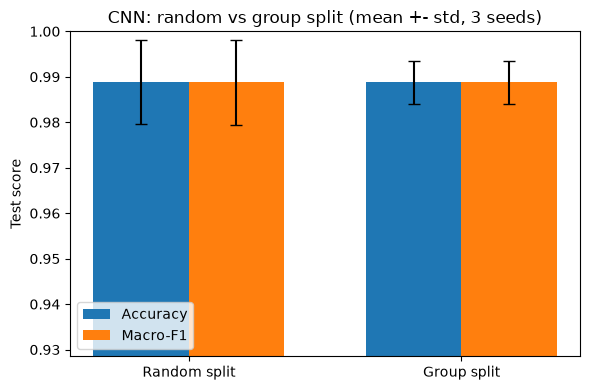

In [15]:
riassunto = leak.groupby('split_type')[['test_accuracy', 'test_macro_f1', 'test_with_dup_in_train']].agg(['mean', 'std'])
print(riassunto.round(4))

tipi = ['random', 'group']
fig, ax = plt.subplots(figsize=(6, 4))
larg = 0.35
for k, (metrica, nome) in enumerate([('test_accuracy', 'Accuracy'), ('test_macro_f1', 'Macro-F1')]):
    medie = [leak[leak['split_type'] == t][metrica].mean() for t in tipi]
    dev = [leak[leak['split_type'] == t][metrica].std() for t in tipi]
    ax.bar(np.arange(2) + (k - 0.5) * larg, medie, larg, yerr=dev, capsize=4, label=nome)
ax.set_xticks(np.arange(2))
ax.set_xticklabels(['Random split', 'Group split'])
ax.set_ylabel('Test score')
ax.set_ylim(min(leak['test_accuracy'].min(), leak['test_macro_f1'].min()) - 0.05, 1.0)
ax.set_title(f'CNN: random vs group split (mean +- std, {len(SEEDS_LEAK)} seeds)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + '/cnn_leakage.png', dpi=150)
plt.show()


Con lo split casuale l'accuracy media è 0.989 ± 0.009, con lo split a gruppi 0.989 ± 0.005: le medie sono uguali alla terza cifra e la differenza è molto più piccola delle deviazioni standard. Quindi **non vedo un'inflazione misurabile** dovuta ai quasi-duplicati, nemmeno con la CNN. Si nota solo che lo split casuale è più variabile (0.979, 0.991, 0.997 contro 0.985, 0.988, 0.994), ma con 3 seed non posso affermare che sia un effetto reale.

Nei tre split casuali il numero di immagini di test con un quasi-duplicato nel train è 55, 56 e 44 su 329 (in media circa 52, cioè circa il 16%), contro 0 negli split a gruppi: il leakage c'è, ma non sembra aiutare questa rete. Ci sono due limiti: 3 seed sono pochi, e con la rete già intorno a 0.99 c'è poco margine per vedere un'inflazione.



## Riassunto

- Una CNN piccola (93.635 parametri, 1.11 MB su disco) allenata da zero senza augmentation, con limite di 100 epoche, arriva a **0.9847 ± 0.0031** di accuracy e **0.9846 ± 0.0031** di macro-F1 sul test (5 seed, split a gruppi).
- Nessun seed arriva al limite di epoche (si fermano a 40-86): decide l'early stopping.
- Supera nettamente la SVM in scala di grigi (0.939) e pareggia, entro il rumore, la SVM con rimozione dello sfondo (0.988), senza bisogno di preprocessing manuale.
- Le curve del seed 0 non mostrano overfitting; la loss di train più alta di quella di validation si spiega con il Dropout e con la media sull'epoca.
- Sul seed 0 gli errori sono 4 su 326 (paper/scissors e paper/rock); rock è la classe più facile (recall 1.000).
- Tempo di predizione di circa 0.48 ms per immagine (seed 0), che userò come riferimento per MobileNet (RQ4).
- Leakage: split casuale 0.989 ± 0.009 contro split a gruppi 0.989 ± 0.005. Anche con la CNN la differenza è dentro il rumore, pur con circa 52 immagini di test (su 329) con un quasi-duplicato nel train negli split casuali.
- Nel prossimo notebook aggiungo la data augmentation con lo stesso limite di 100 epoche, per un confronto equo.
